In [1]:
from pathlib import Path

import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent
ROOT_DIR = PROJECT_DIR.parent
DATA_DIR = ROOT_DIR / "data" / "processed" / "nhl-tracking-pipeline"

SEASON = "20252026"
GAME_ID = 2025020001

In [7]:
events = pd.read_parquet(
    DATA_DIR / "events" / f"{SEASON}.parquet"
)

game_events = events[events["game_id"] == GAME_ID]

print(game_events.shape)
print(game_events.columns.tolist())

goal_ids = game_events["event_id"].unique()
print(goal_ids)

(61, 17)
['season', 'game_id', 'event_id', 'scoring_team_id', 'home_team_id', 'situation_code', 'shot_lead_seconds', 'player_id', 'team_id', 'team_abbrev', 'sweater_number', 'position_code', 'is_goalie', 'is_scorer', 'is_scoring_team', 'd_goalframe', 'd_shotframe']
[ 258  274  366  630 1101]


In [8]:
tracking_path = DATA_DIR / "tracking" / f"{SEASON}.parquet"
dataset = ds.dataset(tracking_path, format="parquet")

In [10]:
event_id = goal_ids[0]

goal_tracking = dataset.to_table(
    filter=(
        (ds.field("game_id") == GAME_ID) &
        (ds.field("event_id") == event_id)
    )
).to_pandas()

print("Event ID:", event_id)
print("Shape:", goal_tracking.shape)

display(goal_tracking.head(20))

Event ID: 258
Shape: (1851, 45)


,season,game_id,event_id,period,time_in_period,abs_game_seconds,situation_code,shot_type,home_team_id,away_team_id,...,is_assist2,is_scoring_team,is_home,x,y,x_att,y_att,dist_to_net_ft,angle_to_net_deg,dist_to_puck_ft
0,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,False,True,3.164000,-1.899000,3.164000,-1.899000,85.857002,-1.270000,72.532997
1,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,False,True,-29.733999,-40.551998,-29.733999,-40.551998,125.468002,-18.860001,28.006001
2,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,False,True,-23.209000,-35.527000,-23.209000,-35.527000,117.698997,-17.570000,35.000999
3,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,False,True,-35.004002,-31.167000,-35.004002,-31.167000,127.860001,-14.110000,24.886000
4,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,True,False,-86.230003,-2.595000,-86.230003,-2.595000,175.248993,-0.850000,48.071999
5,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,False,True,-42.480000,-12.382000,-42.480000,-12.382000,132.061996,-5.380000,32.700001
6,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,False,True,88.388000,0.128000,88.388000,0.128000,0.626000,11.810000,151.878998
7,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,True,False,-58.952999,-32.830002,-58.952999,-32.830002,151.550995,-12.510000,8.565000
8,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,True,False,-53.936001,-10.274000,-53.936001,-10.274000,143.304993,-4.110000,31.264000
9,20252026,2025020001,258,1,10:03,603,1551,snap,13,16,...,False,True,False,-29.330999,-32.467999,-29.330999,-32.467999,122.705002,-15.340000,29.742001


In [11]:
print("Frames:", goal_tracking["frame_idx"].nunique())

print("\nEntity types:")
print(goal_tracking["entity_type"].value_counts())

print("\nUnique players:")
print(goal_tracking["player_id"].nunique())

print("\nObservations per frame:")
print(goal_tracking.groupby("frame_idx").size().describe())

Frames: 140

Entity types:
entity_type
player    1711
puck       140
Name: count, dtype: int64

Unique players:
13

Observations per frame:
count    140.000000
mean      13.221429
std        0.433620
min       12.000000
25%       13.000000
50%       13.000000
75%       13.000000
max       14.000000
dtype: float64


In [18]:
skaters = pd.read_parquet(
    DATA_DIR / "edge_skaters" / f"{SEASON}.parquet"
)
players = pd.read_parquet(
    DATA_DIR / "players.parquet"
)

skaters = skaters.merge(
    players,
    left_on="player_id",
    right_on="playerId",
    how="left"
)

scorer_id = goal_tracking["pbp_scorer_id"].dropna().iloc[0]

scorer = skaters[skaters["player_id"] == scorer_id]

display(scorer)

,season,player_id,position,team_abbrev,games_played,top_shot_speed_mph,top_shot_speed_pctile,skating_speed_max_mph,skating_speed_max_pctile,bursts_over_20,...,sog_all,goals_all,shooting_pctg,off_zone_pctg,def_zone_pctg,neu_zone_pctg,playerId,firstName,lastName,positionCode
795,20252026,8483493,C,CHI,66,94.0,0.9492,23.7618,0.9772,190,...,138,15,0.1087,0.414937,0.405856,0.179207,8483493,Frank,Nazar,C


In [19]:
# Determine the goal frame
goal_frame = goal_tracking["goal_frame_idx"].dropna().iloc[0]

# Keep observations up to and including the goal
goal_data = goal_tracking[
    goal_tracking["frame_idx"] <= goal_frame
].copy()

# Sort chronologically
goal_data = goal_data.sort_values("frame_idx")

# Frank Nazar
scorer = goal_data[
    goal_data["player_id"] == scorer_id
].sort_values("frame_idx")

# Puck
puck = goal_data[
    goal_data["entity_type"].str.lower() == "puck"
].sort_values("frame_idx")

print("Goal frame:", goal_frame)
print("Scorer observations:", len(scorer))
print("Puck observations:", len(puck))

Goal frame: 103
Scorer observations: 104
Puck observations: 104


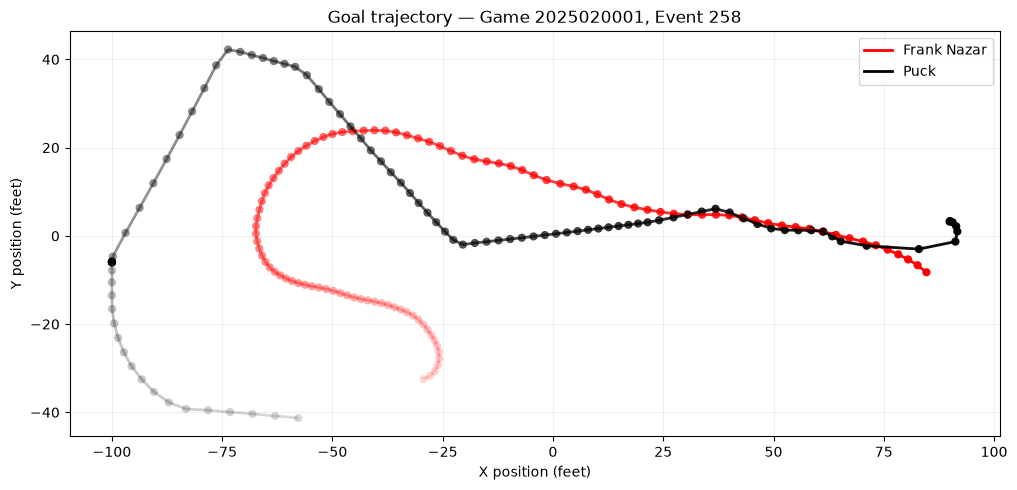

In [20]:
import numpy as np
from matplotlib.collections import LineCollection

fig, ax = plt.subplots(figsize=(12, 8))

def plot_trajectory(data, color, label):
    x = data["x"].to_numpy()
    y = data["y"].to_numpy()

    points = np.column_stack([x, y])
    segments = np.stack([points[:-1], points[1:]], axis=1)

    # Transparency decreases with time
    alpha = np.linspace(0.15, 1.0, len(points))

    # Line segments
    colors = [
        (*plt.matplotlib.colors.to_rgb(color), a)
        for a in alpha[:-1]
    ]

    lc = LineCollection(
        segments,
        colors=colors,
        linewidths=2
    )
    ax.add_collection(lc)

    # Circular markers
    ax.scatter(
        x, y,
        s=35,
        c=[(*plt.matplotlib.colors.to_rgb(color), a) for a in alpha],
        edgecolors="none"
    )

    # Legend entry
    ax.plot([], [], color=color, linewidth=2, label=label)


plot_trajectory(scorer, "red", "Frank Nazar")
plot_trajectory(puck, "black", "Puck")

ax.set_xlabel("X position (feet)")
ax.set_ylabel("Y position (feet)")
ax.set_title(f"Goal trajectory — Game {GAME_ID}, Event {event_id}")

ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.2)

plt.show()